In [1]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sys
import os
import seaborn as sns

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.insert(0, src_dir)

#import the module
import standardised_pipeline_utils
import corr_utils

from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from scipy.stats import pearsonr
from scipy.cluster.hierarchy import fcluster
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram
from sklearn.utils import resample
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

from sklearn.decomposition import PCA

from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import pairwise_distances
import networkx as nx



## Pearson


### Datasets

In [2]:
pearson = load('data/full_pearson100.joblib')
pearson


,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A2ML1-AS2,A2MP1,A3GALT2,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.0,0.0,0.0,0.166604,...,0.000000,0.000000,0.000000,0.000000,0.0,0.070655,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.089634,0.000000,0.0,0.0,0.0,0.000000,...,-0.098537,0.000000,0.000000,0.000000,0.0,-0.074209,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,0.000000,-0.147446,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,0.094037,-0.076360,0.0,0.0,0.0,0.094948,...,0.148686,0.104587,0.101981,0.000000,0.0,0.000000,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,-0.075800,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.148775,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164620,0.0,0.0,0.0,0.000000,...,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.157165,0.106069


In [3]:
transcriptomics_filtered = load('data/transcriptomics_kde_filtered.joblib')
transcriptomics_filtered

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607,1.575312,5.311430,4.531069,0.056584,0.124328,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000,0.111031,5.229972,4.095924,0.070389,0.014355,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541,0.933573,6.011898,5.564378,1.618239,0.250962,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,0.124328,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696,3.751678,6.262847,3.874797,0.056584,0.070389,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.263034,4.168321,5.244887,5.409391,0.189034,2.446256,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.150560,2.163499,6.280585,4.335569,0.014355,4.980939,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.070389,0.042644,5.667608,3.218781,0.056584,0.000000,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777


In [4]:
#Remove genes filtered out in the filtering procedure
pearson = pearson[transcriptomics_filtered.columns]
pearson

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.124962,0.000000,0.000000,0.000000,0.000000,0.0,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.160298,0.0,0.000000,...,-0.078537,-0.098537,0.000000,0.000000,0.000000,0.0,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,-0.113664,0.000000,0.470513,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,-0.147446,-0.121553,0.168963,0.000000,0.0,0.000000,...,0.191555,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,-0.076360,0.000000,0.000000,0.000000,0.0,-0.133701,...,0.092193,0.148686,0.104587,0.101981,0.000000,0.0,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,0.000000,-0.156288,0.190009,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,-0.164620,-0.119140,0.155437,0.000000,0.0,0.000000,...,0.222471,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.157165,0.106069


In [5]:
# 1. Replace infinite values with NaN.
pearson_clean = pearson.replace([np.inf, -np.inf], np.nan)

# 2. Drop rows and columns with NaN values.
pearson_clean = pearson_clean.dropna(axis=0, how='any').dropna(axis=1, how='any')

# 3. Drop rows and columns with zero variance to avoid division-by-zero issues.
pearson_clean = pearson_clean.loc[pearson_clean.var(axis=1) != 0, :]
pearson_clean = pearson_clean.loc[:, pearson_clean.var(axis=0) != 0]

# Optional: Print shapes to ensure cleaning worked.
print("Shape after cleaning:", pearson_clean.shape)


Shape after cleaning: (5113, 22607)


### Pearson Correlations full distribution 

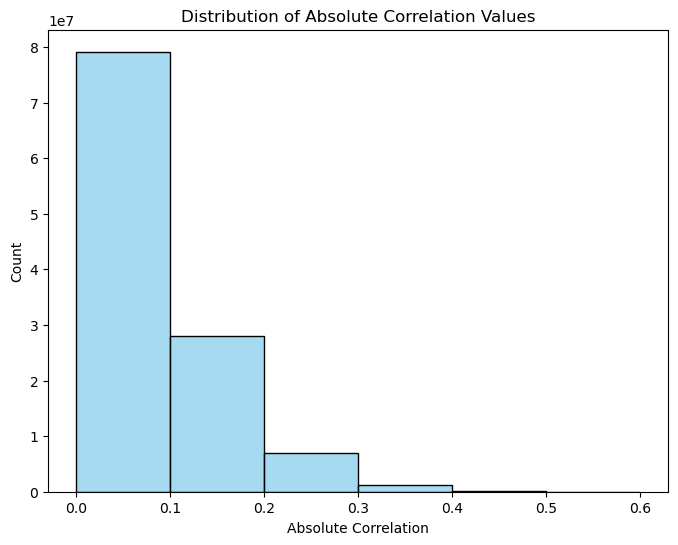

In [5]:
abs_values = pearson.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='skyblue', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


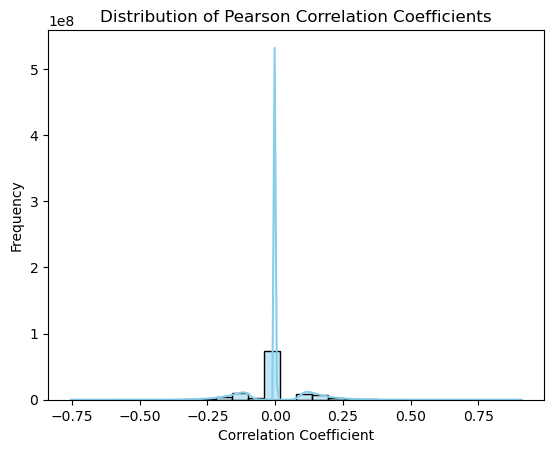

In [6]:
data = pearson.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='skyblue', kde=True)

# Optional customizations
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

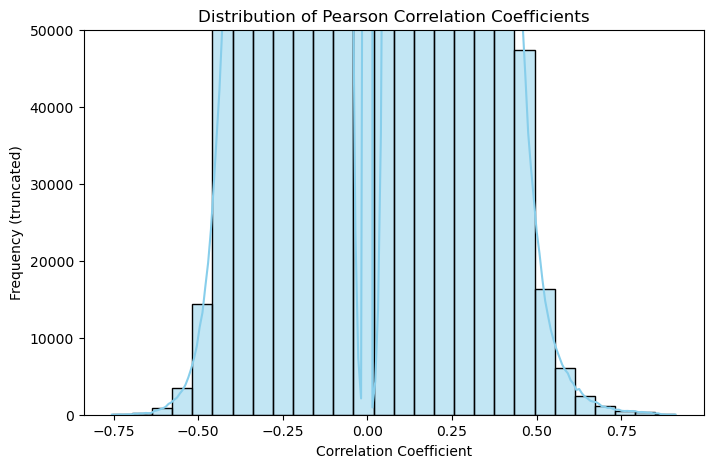

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data, color='skyblue', kde=True)
plt.ylim(top=50000)  # Adjust for zeros
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency (truncated)")
plt.show()

another approach, filter out zeros

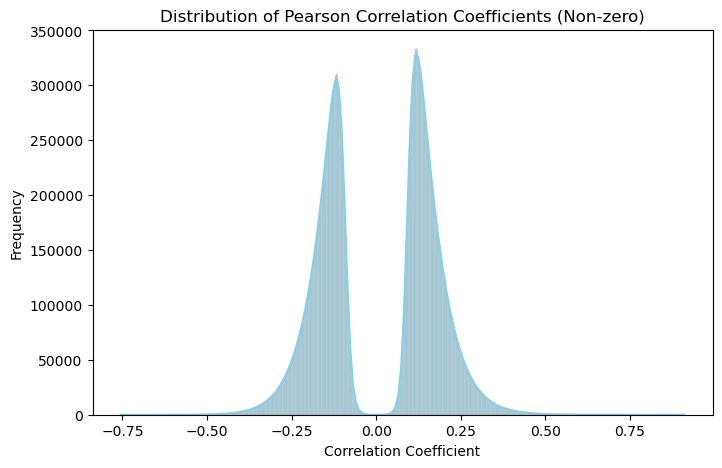

In [8]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='skyblue', kde=True)
plt.title("Distribution of Pearson Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()


### Plot protein - # correlated genes

how many zeros


In [9]:
zero_counts = (pearson == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (pearson.abs() > t).sum(axis=1) for t in thresholds}

In [12]:
# 1. Replace infinite values with NaN.
pearson_clean = pearson.replace([np.inf, -np.inf], np.nan)

# 2. Drop rows and columns with NaN values.
pearson_clean = pearson_clean.dropna(axis=0, how='any').dropna(axis=1, how='any')

# 3. Drop rows and columns with zero variance to avoid division-by-zero issues.
pearson_clean = pearson_clean.loc[pearson_clean.var(axis=1) != 0, :]
pearson_clean = pearson_clean.loc[:, pearson_clean.var(axis=0) != 0]

# Optional: Print shapes to ensure cleaning worked.
print("Shape after cleaning:", pearson_clean.shape)

Shape after cleaning: (5113, 22607)


In [13]:
def print_summary():
    summary = pd.DataFrame({"Zero Correlations": zero_counts})
    
    # Compute median number of zero correlations per protein
    median_zeros = zero_counts.median()
    
    for t in thresholds:
        # Count how many correlations are above the threshold per protein
        above_threshold = (pearson_clean.T > t).sum(axis=1)
        
        # Add count and median columns to the summary
        summary[f"Correlated > {t}"] = thresh_counts[t]
        summary[f"Median > {t}"] = above_threshold.median()

    # Print the table
    print(summary)

    # Print medians
    print("\nMedian Number of Zero Correlations per Protein:", median_zeros)
    for t in thresholds:
        median_corr = (pearson.T > t).sum(axis=1).median()
        print(f"Median Number of Correlations > {t} per Protein: {median_corr}")


In [14]:
print_summary()

          Zero Correlations  Correlated > 0.1  Median > 0.1  Correlated > 0.2  \
proteins                                                                        
A2M                   12876              8462         838.0              2222   
AAAS                  17584              4102         838.0               309   
AACS                  18194              3646         838.0               168   
AAGAB                 14633              6672         838.0               718   
AAK1                  12991              8733         838.0              2506   
...                     ...               ...           ...               ...   
ZRANB2                15263              6506         838.0               791   
ZW10                  19607              2333         838.0                86   
ZWILCH                15120              6600         838.0               706   
ZYX                   14511              7244         838.0              1473   
ZZZ3                  15695 

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

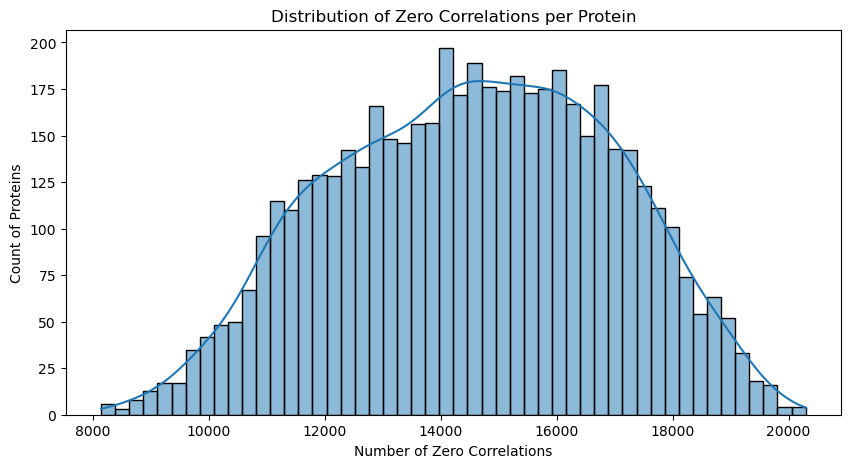

In [15]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

### Threshold counts

#### Above 0.1 absolute correlation

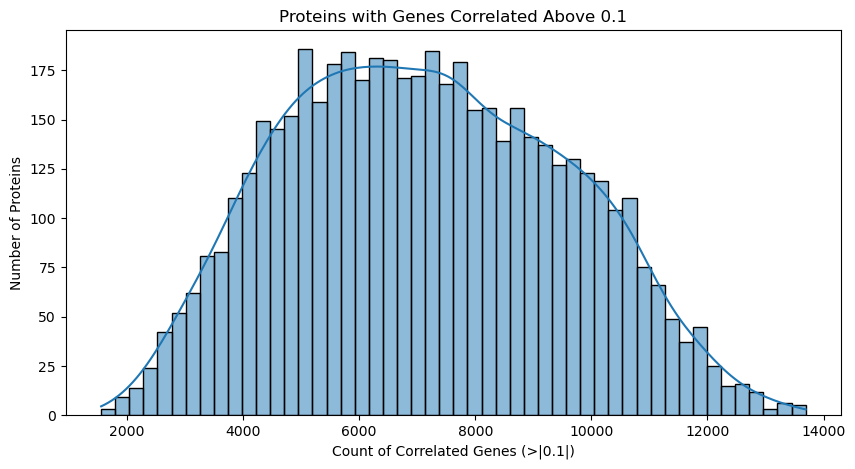

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

#### Above 0.2 absolute correlation

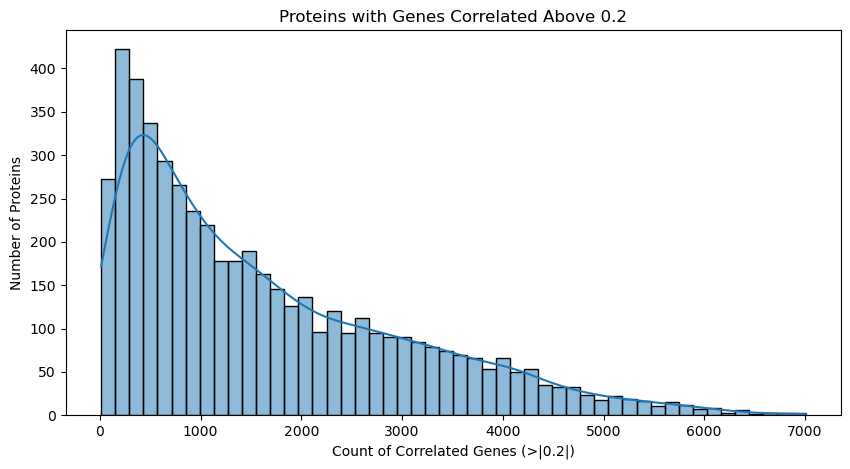

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

#### Above 0.3 absolute correlation

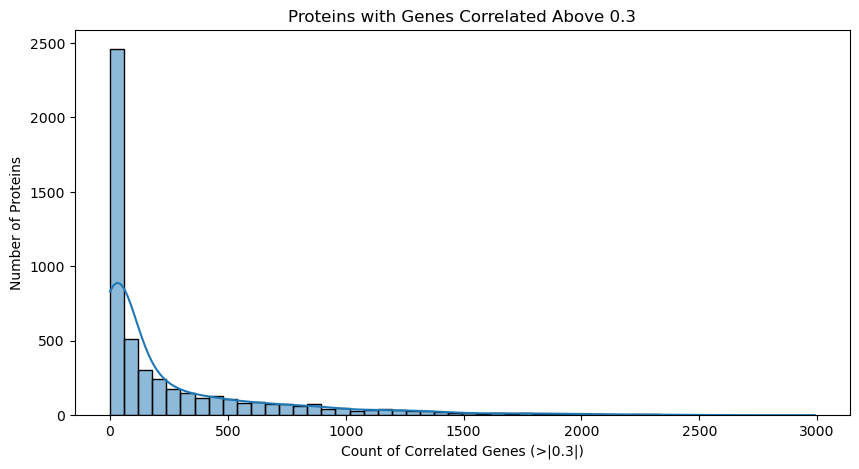

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()

### Clustermap

In [19]:
#pip install fastcluster

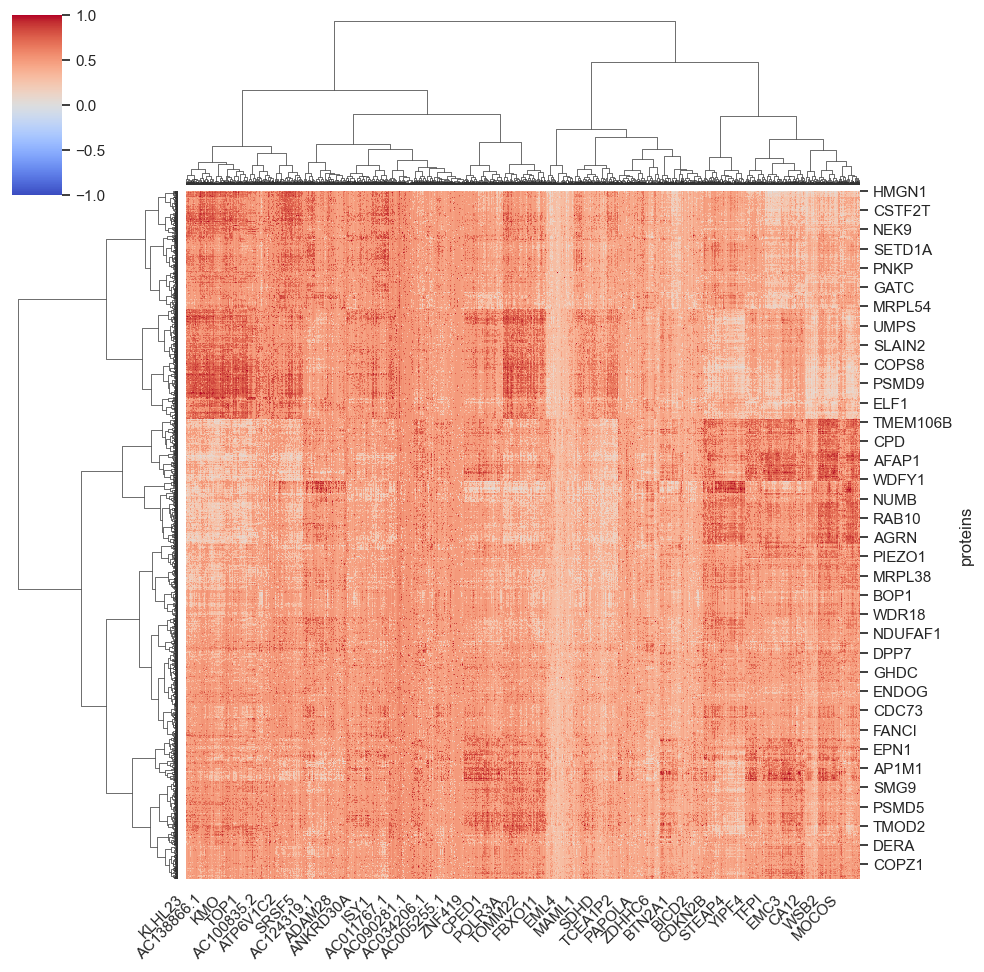

In [21]:
# Create the clustermap.
sns.set_theme(style="white")
g = sns.clustermap(
    pearson_clean,
    method="ward",         # Clustering method
    metric="euclidean",    # Distance metric
    cmap="coolwarm",           # Color map for correlation data
    center=0,              # Center the colormap at zero
    vmin=-1, vmax=1,       # Expected correlation range
    standard_scale=1,      # Standardize each row (protein)
    figsize=(10, 10)       # Figure size
)

# 5. Rotate x-axis labels for readability.
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
plt.show()


Dendogram for clustering

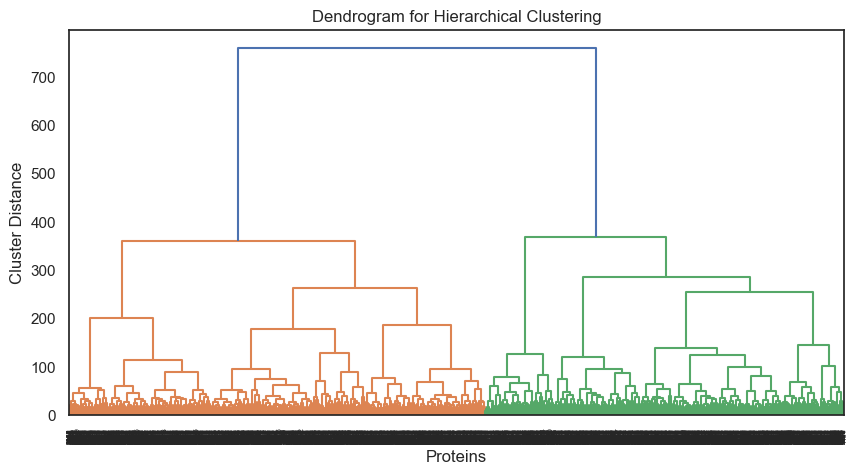

In [22]:
# Generate the hierarchical linkage matrix from the cleaned Pearson matrix
row_linkage = sch.linkage(pearson_clean, method="ward", metric="euclidean")

# 1. Dendrogram Method (Manual Inspection Required)
corr_utils.plot_dendrogram(row_linkage)  # Visually inspect and manually choose a number



Elbow plot

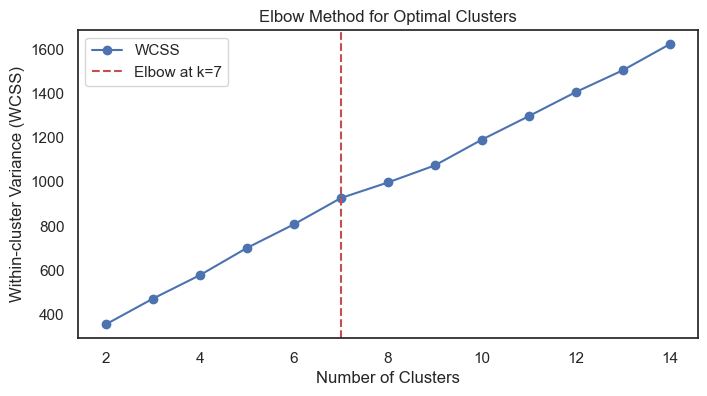

In [23]:

# 2. Elbow Method
elbow_k = corr_utils.elbow_method(pearson_clean, row_linkage)

# 3. Silhouette Score Method
silhouette_k = corr_utils.silhouette_method(pearson_clean, row_linkage)

### Consensus Clustering

In [6]:
# Parameters
num_bootstraps = 10  # Number of bootstrap samples
max_clusters = 7    # Max number of clusters to evaluate

# Number of proteins (rows) in your dataset
n_proteins = pearson_clean.shape[0]  # should be 5113

# Create consensus matrices - correct initialization
consensus_matrices = np.zeros((max_clusters - 1, n_proteins, n_proteins))

# Perform consensus clustering for k = 2 to max_clusters
for k in range(2, max_clusters + 1):
    coassociation_matrix = np.zeros((n_proteins, n_proteins))
    
    # Bootstrap sampling and clustering
    for _ in range(num_bootstraps):
        # Resample proteins (rows) only
        sampled_data = resample(pearson_clean, replace=True)
        row_linkage = sch.linkage(sampled_data, method="ward", metric="euclidean")
        clusters = sch.fcluster(row_linkage, k, criterion="maxclust")
    
        # Update coassociation matrix
        for i in range(len(clusters)):
            for j in range(len(clusters)):
                if clusters[i] == clusters[j]:
                    coassociation_matrix[i, j] += 1
    
    # Normalize to obtain consensus matrix for current k (stored at index k-2)
    consensus_matrices[k - 2] = coassociation_matrix / num_bootstraps

In [7]:
# Example usage with your consensus matrices:
corr_utils.visualize_all_consensus_matrices(consensus_matrices)

Cluster Stability Metrics:
   k       PAC  Mean_Consensus  Median_Consensus   Entropy
0  2  0.996857        0.557436               0.6  0.914319
1  3  0.988426        0.359742               0.4  0.864960
2  4  0.967473        0.288896               0.3  0.788772
3  5  0.919486        0.222538               0.2  0.683310
4  6  0.879054        0.190317               0.2  0.619230
5  7  0.837468        0.166141               0.2  0.564812


,k,PAC,Mean_Consensus,Median_Consensus,Entropy
0,2,0.996857,0.557436,0.6,0.914319
1,3,0.988426,0.359742,0.4,0.864960
2,4,0.967473,0.288896,0.3,0.788772
3,5,0.919486,0.222538,0.2,0.683310
4,6,0.879054,0.190317,0.2,0.619230
5,7,0.837468,0.166141,0.2,0.564812


### Metrics on clusters

#### number of clusters according to elbow score

In [8]:
# ------------------------------
# Extracting Cluster Assignments
# ------------------------------

# The row dendrogram linkage is stored in g.dendrogram_row.linkage.
row_linkage = g.dendrogram_row.linkage

# Choose a criterion for forming flat clusters. Here we use a maximum of 4 clusters.
# You can change max_clusters or use a distance threshold with criterion='distance'
max_clusters = elbow_k
cluster_labels = fcluster(row_linkage, max_clusters, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_elbow.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_elbow.csv'.")



NameError: name 'g' is not defined

#### number of clusters according to silhouette score

In [ ]:
max_clusters = silhouette_k
cluster_labels = fcluster(row_linkage, max_clusters, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_sil.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        2
1       AAAS        2
2       AACS        2
3      AAGAB        1
4       AAK1        2
...      ...      ...
5108  ZRANB2        1
5109    ZW10        2
5110  ZWILCH        1
5111     ZYX        2
5112    ZZZ3        1

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters.csv'.


Compute Metrics different number of clusters to se the best

In [ ]:
# Define range of cluster sizes
k_range = range(2, 8)

# Store results
results = []
wcss_values = []  # For the elbow method

for k in k_range:
    # Assign each protein to a cluster
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")

    # Convert to DataFrame
    cluster_df = pd.DataFrame({"Protein": pearson_clean.index, "Cluster": clusters})

    # Count proteins per cluster
    cluster_sizes = cluster_df["Cluster"].value_counts().sort_index()

    # Compute Within-Cluster Variance (WCSS)
    wcss = sum(np.var(pearson_clean[clusters == i], axis=0).sum() for i in np.unique(clusters))
    wcss_values.append(wcss)  # Store WCSS for elbow method

    # Compute Silhouette Score
    sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')

    # Compute Dunn Index
    dunn = corr_utils.dunn_index(pearson_clean.values, clusters)

    # Compute Calinski-Harabasz Index
    calinski_harabasz = calinski_harabasz_score(pearson_clean, clusters)

    # Compute Davies-Bouldin Index
    davies_bouldin = davies_bouldin_score(pearson_clean, clusters)

    # Store results
    results.append((k, cluster_sizes.to_dict(), wcss, sil_score, dunn, calinski_harabasz, davies_bouldin))

# Print results
for k, sizes, wcss, sil_score, dunn, calinski_harabasz, davies_bouldin in results:
    print(f"\nClusters: {k}")
    print(f"Cluster Sizes: {sizes}")
    print(f"Within-Cluster Variance (WCSS): {wcss:.4f}")
    print(f"Silhouette Score: {sil_score:.4f}")
    print(f"Dunn Index: {dunn:.4f}")
    print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
    print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")


NameError: name 'row_linkage' is not defined

Deeper analysis in 2-clusters

In [ ]:
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")
unique_clusters = np.unique(clusters)

cluster_stats = []

for cl in unique_clusters:
    # Get indices of proteins in the cluster
    cluster_indices = np.where(clusters == cl)[0]
    proteins = pearson_clean.index[cluster_indices]
    cluster_data = pearson_clean.iloc[cluster_indices, :]
    
    # Basic statistics
    size = len(proteins)
    centroid = cluster_data.mean(axis=0)
    intra_corr = cluster_data.values.flatten()  # all correlations within the cluster (can be filtered further)
    within_variance = cluster_data.var().sum()
    
    # Optionally, compute network-based or centrality measures here if needed
    
    cluster_stats.append({
        "Cluster": cl,
        "Size": size,
        "Centroid_Mean": centroid.mean(),  # overall average for centroid profile
        "Within_Variance": within_variance,
        "Intra_Cluster_Correlation_Mean": np.nanmean(intra_corr)
    })

# Convert to DataFrame for easier viewing
cluster_stats_df = pd.DataFrame(cluster_stats)
print(cluster_stats_df)

# Global clustering metrics (computed on all data with provided labels)
sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')
calinski_harabasz = calinski_harabasz_score(pearson_clean, clusters)
davies_bouldin = davies_bouldin_score(pearson_clean, clusters)

print(f"Global Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")



   Cluster  Size  Centroid_Mean  Within_Variance  \
0        1  1696       0.007302       154.081726   
1        2  3417       0.001269       189.665451   

   Intra_Cluster_Correlation_Mean  
0                        0.007302  
1                        0.001269  
Global Silhouette Score: 0.1989
Calinski-Harabasz Index: 1578.7773
Davies-Bouldin Index: 1.6234


Deeper analysis in 3-Cluster

In [ ]:
clusters = sch.fcluster(row_linkage, 3, criterion="maxclust")
unique_clusters = np.unique(clusters)

cluster_stats = []

for cl in unique_clusters:
    # Get indices of proteins in the cluster
    cluster_indices = np.where(clusters == cl)[0]
    proteins = pearson_clean.index[cluster_indices]
    cluster_data = pearson_clean.iloc[cluster_indices, :]
    
    # Basic statistics
    size = len(proteins)
    centroid = cluster_data.mean(axis=0)
    intra_corr = cluster_data.values.flatten()  # all correlations within the cluster (can be filtered further)
    within_variance = cluster_data.var().sum()
    
    # Optionally, compute network-based or centrality measures here if needed
    
    cluster_stats.append({
        "Cluster": cl,
        "Size": size,
        "Centroid_Mean": centroid.mean(),  # overall average for centroid profile
        "Within_Variance": within_variance,
        "Intra_Cluster_Correlation_Mean": np.nanmean(intra_corr)
    })

# Convert to DataFrame for easier viewing
cluster_stats_df = pd.DataFrame(cluster_stats)
print(cluster_stats_df)

# Global clustering metrics (computed on all data with provided labels)
sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')
calinski_harabasz = calinski_harabasz_score(pearson_clean, clusters)
davies_bouldin = davies_bouldin_score(pearson_clean, clusters)

print(f"Global Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")



### PCA

PCA 2-clusters

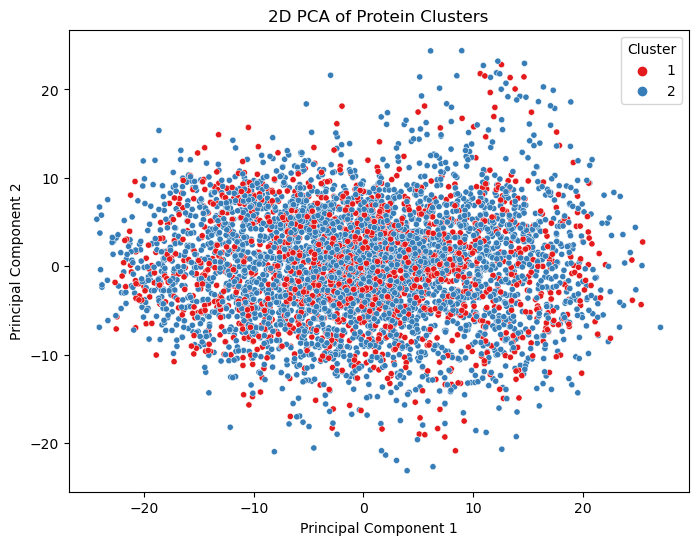

In [10]:
# Compute PCA on the cleaned data, reducing to 2 dimensions
clusters = sch.fcluster(row_linkage, 2 , criterion="maxclust")
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pearson_clean.values)

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=pearson_clean.index)
pca_df["Cluster"] = clusters  # Add the cluster assignments

# Plot the clusters in 2D using a scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=20)
plt.title("2D PCA of Protein Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()


PCA 3-Clusters

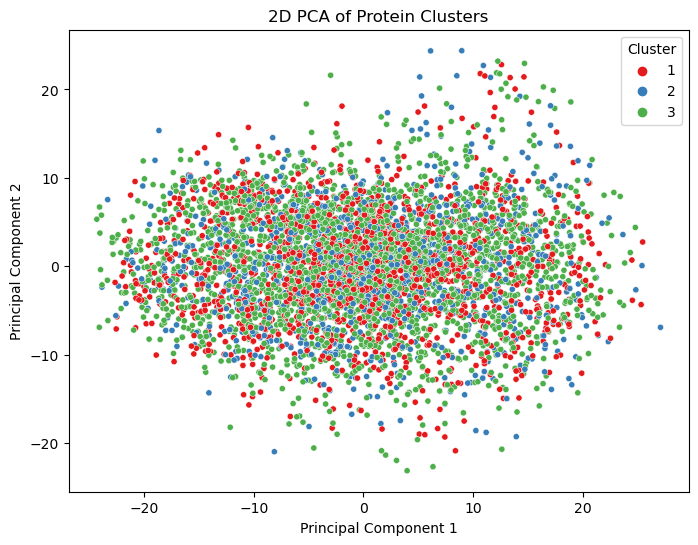

In [11]:
# Compute PCA on the cleaned data, reducing to 2 dimensions
clusters = sch.fcluster(row_linkage, 3 , criterion="maxclust")
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pearson_clean.values)

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=pearson_clean.index)
pca_df["Cluster"] = clusters  # Add the cluster assignments

# Plot the clusters in 2D using a scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=20)
plt.title("2D PCA of Protein Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

PCA All Clusters

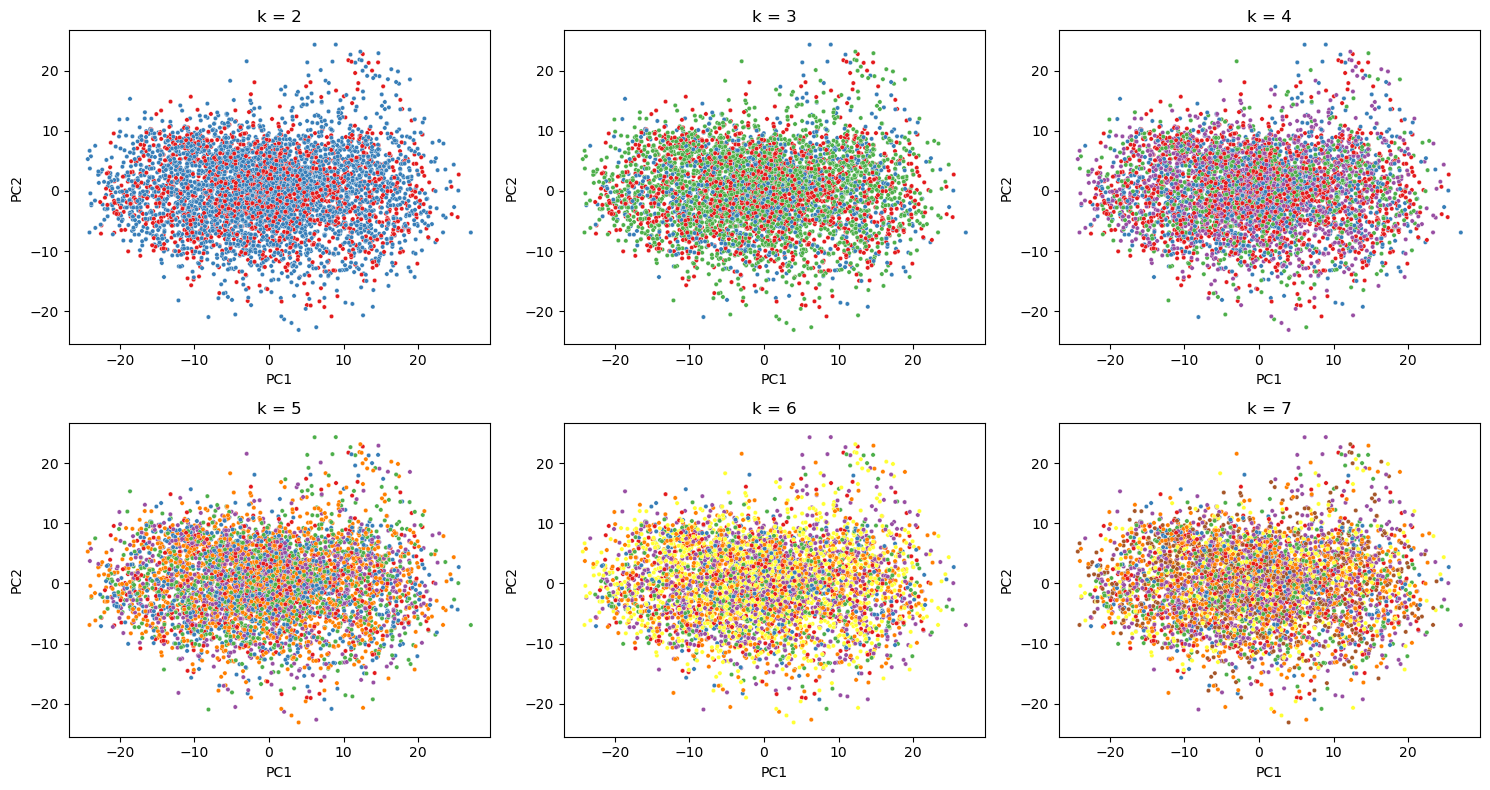

In [12]:
# Create a 2x5 grid for plots with a reduced overall figure size
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # flatten to easily iterate over

# Loop over cluster numbers from 2 to 10
for i, k in enumerate(range(2, 8)):
    # Compute clusters using hierarchical clustering
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")
    
    # Perform PCA on the cleaned data
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(pearson_clean.values)
    
    # Create DataFrame for PCA results with cluster assignments
    pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=pearson_clean.index)
    pca_df["Cluster"] = clusters
    
    # Plot on the corresponding axis
    ax = axes[i]
    sns.scatterplot(
        data=pca_df, 
        x="PC1", 
        y="PC2", 
        hue="Cluster", 
        palette="Set1", 
        s=10, 
        ax=ax,
        legend=False  # Disable legend for individual subplots
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

save 3 clusters

In [ ]:
cluster_labels = fcluster(row_linkage, 3, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_3.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_3.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        3
1       AAAS        3
2       AACS        3
3      AAGAB        1
4       AAK1        2
...      ...      ...
5108  ZRANB2        1
5109    ZW10        3
5110  ZWILCH        1
5111     ZYX        3
5112    ZZZ3        1

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters_3.csv'.


save 4 clusters

In [ ]:

cluster_labels = fcluster(row_linkage, 4, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_4.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_4.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        4
1       AAAS        3
2       AACS        3
3      AAGAB        1
4       AAK1        2
...      ...      ...
5108  ZRANB2        1
5109    ZW10        4
5110  ZWILCH        1
5111     ZYX        4
5112    ZZZ3        1

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters_4.csv'.


#### Statistical analysis of clusters

In [ ]:

# Set a threshold for average gene correlation (example threshold: 0.5)
threshold = 0.1

# Create a copy of your data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters  # clusters should align with the rows of pearson_clean

# Dictionary to store summary statistics for each cluster
cluster_stats = {}

# Loop over each cluster
for cluster_label, group in data.groupby("Cluster"):
    # Remove the cluster column so that only gene correlation values remain
    group_data = group.drop(columns=["Cluster"])
    
    # Compute gene-wise statistics for the proteins in this cluster
    gene_means = group_data.mean(axis=0)
    gene_vars = group_data.var(axis=0)
    gene_min = group_data.min(axis=0)
    gene_max = group_data.max(axis=0)
    
    # Aggregate these gene-level stats to get cluster-level summary measures.
    # For example, we compute the average of the gene means, standard deviation, etc.
    cluster_summary = {
        "mean_of_gene_means": gene_means.mean(),
        "std_of_gene_means": gene_means.std(),
        "mean_of_gene_vars": gene_vars.mean(),
        "std_of_gene_vars": gene_vars.std(),
        "average_min": gene_min.mean(),
        "average_max": gene_max.mean(),
        "num_genes_above_threshold": (gene_means > threshold).sum(),
        "total_genes": len(gene_means)
    }
    
    cluster_stats[cluster_label] = cluster_summary

# Convert the dictionary to a DataFrame for easier viewing
stats_df = pd.DataFrame(cluster_stats).T
stats_df.index.name = "Cluster"
print(stats_df)


         mean_of_gene_means  std_of_gene_means  mean_of_gene_vars  \
Cluster                                                             
1                  0.003346           0.090889           0.004446   
2                 -0.000818           0.049794           0.005096   
3                  0.018867           0.072470           0.004525   
4                  0.010370           0.104826           0.005134   
5                  0.006021           0.102505           0.006337   
6                 -0.022570           0.137690           0.005126   
7                 -0.011286           0.102007           0.005580   
8                 -0.012943           0.050999           0.005041   
9                  0.000600           0.022852           0.004880   
10                 0.021414           0.074645           0.006899   
11                 0.010169           0.039089           0.004721   

         std_of_gene_vars  average_min  average_max  \
Cluster                                        

2 clusters

In [ ]:
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")
threshold = 0.1

# Create a copy of your data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters  # clusters should align with the rows of pearson_clean

# Dictionary to store summary statistics for each cluster
cluster_stats = {}

# Loop over each cluster
for cluster_label, group in data.groupby("Cluster"):
    # Remove the cluster column so that only gene correlation values remain
    group_data = group.drop(columns=["Cluster"])
    
    # Compute gene-wise statistics for the proteins in this cluster
    gene_means = group_data.mean(axis=0)
    gene_vars = group_data.var(axis=0)
    gene_min = group_data.min(axis=0)
    gene_max = group_data.max(axis=0)
    
    # Aggregate these gene-level stats to get cluster-level summary measures.
    # For example, we compute the average of the gene means, standard deviation, etc.
    cluster_summary = {
        "mean_of_gene_means": gene_means.mean(),
        "std_of_gene_means": gene_means.std(),
        "mean_of_gene_vars": gene_vars.mean(),
        "std_of_gene_vars": gene_vars.std(),
        "average_min": gene_min.mean(),
        "average_max": gene_max.mean(),
        "num_genes_above_threshold": (gene_means > threshold).sum(),
        "total_genes": len(gene_means)
    }
    
    cluster_stats[cluster_label] = cluster_summary

# Convert the dictionary to a DataFrame for easier viewing
stats_df = pd.DataFrame(cluster_stats).T
stats_df.index.name = "Cluster"
print(stats_df)


         mean_of_gene_means  std_of_gene_means  mean_of_gene_vars  \
Cluster                                                             
1                  0.007302           0.067094           0.006816   
2                  0.001269           0.038989           0.008390   

         std_of_gene_vars  average_min  average_max  \
Cluster                                               
1                0.004292    -0.248439     0.295052   
2                0.005729    -0.304282     0.363319   

         num_genes_above_threshold  total_genes  
Cluster                                          
1                           1971.0      22607.0  
2                            268.0      22607.0  


### Other analyses on 2, 3 clusters

#### 2 clusters

Violin Plots

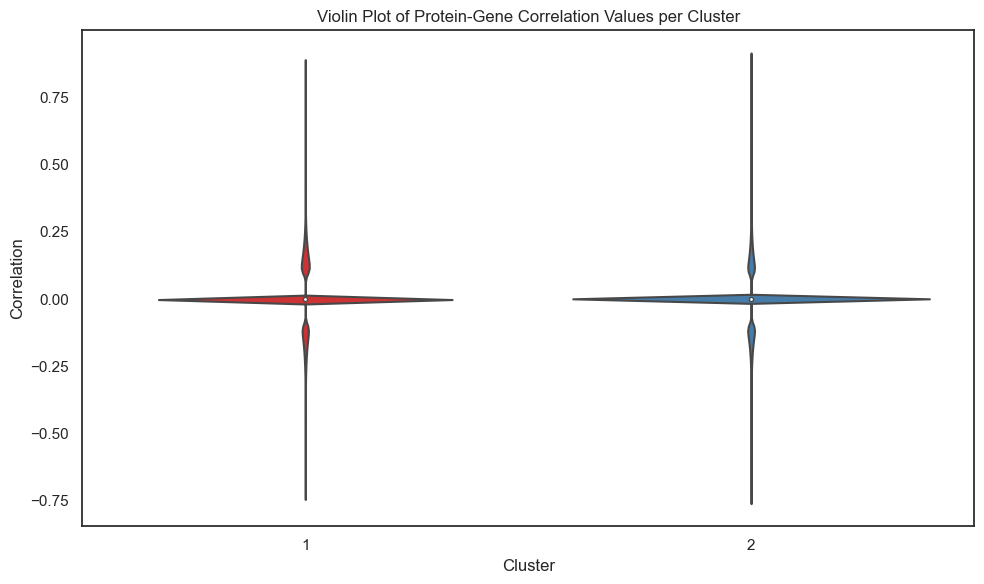

In [ ]:
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")
# ----- 1. Distribution Plots of Correlation Values ----- #

# (a) Violin Plot: Distribution of all protein–gene correlations per cluster.
# Add the cluster labels to the data:
# 1. Copy data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters

# 2. Name the index "Protein"
data.index.name = "Protein"

# 3. Reset the index so "Protein" becomes a column
data.reset_index(inplace=True)

# 4. Melt the DataFrame, specifying the correct 'id_vars'
data_melted = data.melt(
    id_vars=["Protein", "Cluster"],
    var_name="Gene",
    value_name="Correlation"
)

# 5. Plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=data_melted, x="Cluster", y="Correlation", palette="Set1")
plt.title("Violin Plot of Protein-Gene Correlation Values per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Correlation")
plt.ylim(-0.3, 0.3)  # Zoom in on y-axis
plt.tight_layout()
plt.show()





Histogram Density

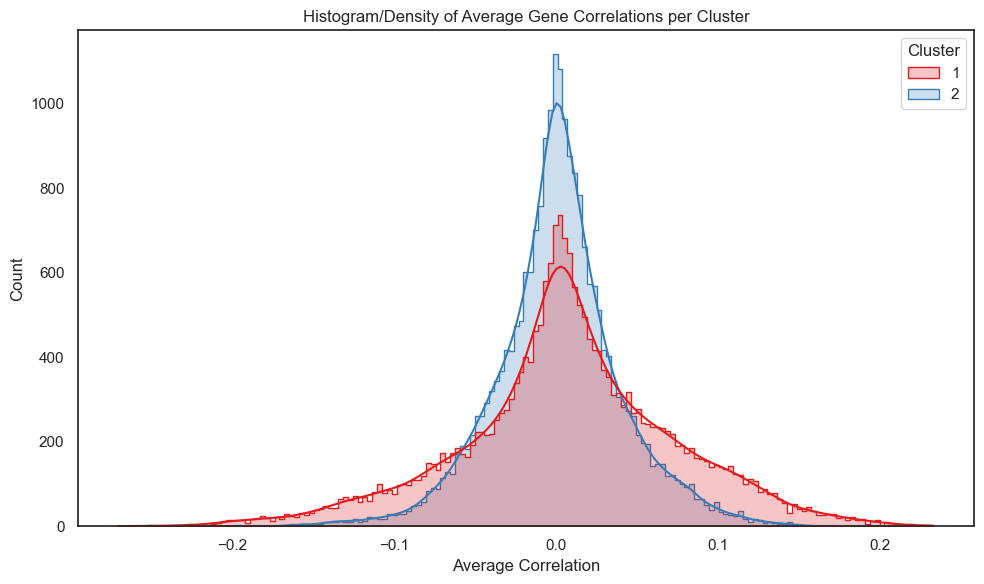

Cluster Centroids (Average Profiles):
             A1BG  A1BG-AS1      A1CF       A2M     A2ML1    A4GALT      AAAS  \
Cluster                                                                         
1        0.052697  0.041527  0.001671 -0.035669 -0.056942 -0.130295  0.135283   
2       -0.024340 -0.017794 -0.006523  0.023690  0.014172  0.057664 -0.062467   

             AACS    AACSP1     AADAC  ...    ZWILCH     ZWINT      ZXDA  \
Cluster                                ...                                 
1       -0.007268  0.004203 -0.051945  ...  0.008123  0.046601  0.001413   
2        0.010339  0.000215  0.026878  ...  0.003930 -0.012715  0.005450   

             ZXDB      ZXDC    ZYG11A    ZYG11B       ZYX     ZZEF1      ZZZ3  
Cluster                                                                        
1        0.018755  0.077743  0.007604 -0.007534 -0.129680  0.064359  0.016825  
2        0.001571 -0.015335  0.004780  0.024285  0.080283 -0.025516  0.012170  

[2 rows x 2

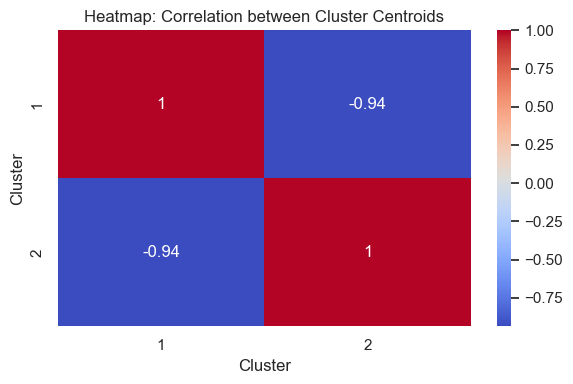


Euclidean distances between Cluster Centroids:
Cluster          1          2
Cluster                      
1         0.000000  15.740117
2        15.740117   0.000000


In [ ]:
# Ensure 'Cluster' column is categorical if it's not numeric
if 'Cluster' in data.columns:
    data['Cluster'] = data['Cluster'].astype(str)  # Convert to string if needed

# (b) Histogram/Density Plot: Distribution of average gene correlations in each cluster.
# Exclude non-numeric columns before computing the mean
numeric_cols = data.select_dtypes(include=['number']).columns  # Select only numeric columns
cluster_averages = data.groupby('Cluster')[numeric_cols].mean()

# Melt the cluster averages (each row: one gene in one cluster, with its average correlation)
cluster_avg_melted = cluster_averages.reset_index().melt(id_vars='Cluster', var_name='Gene', value_name='Avg_Correlation')

# Plot the histogram/density plot
plt.figure(figsize=(10, 6))
sns.histplot(data=cluster_avg_melted, x='Avg_Correlation', hue='Cluster', palette='Set1', kde=True, element='step')
plt.title("Histogram/Density of Average Gene Correlations per Cluster")
plt.xlabel("Average Correlation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()



Cluster-Level “Profiles” 

In [ ]:
# ----- 2. Cluster-Level “Profiles” ----- #

# Compute the centroid (average profile) for each cluster (across genes)
centroids = cluster_averages  # Already computed

print("Cluster Centroids (Average Profiles):")
print(centroids)

# (a) Compute pairwise correlation between centroids (transposing so genes are observations)
centroid_corr = centroids.T.corr()
print("\nCorrelation between Cluster Centroids:")
print(centroid_corr)

# Plot correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(centroid_corr, annot=True, cmap='coolwarm')
plt.title("Heatmap: Correlation between Cluster Centroids")
plt.tight_layout()
plt.show()

# (b) Compute Euclidean distances between centroids
centroid_dist = pd.DataFrame(squareform(pdist(centroids)), index=centroids.index, columns=centroids.index)

print("\nEuclidean distances between Cluster Centroids:")
print(centroid_dist)


#### 3-clusters

Violin plot

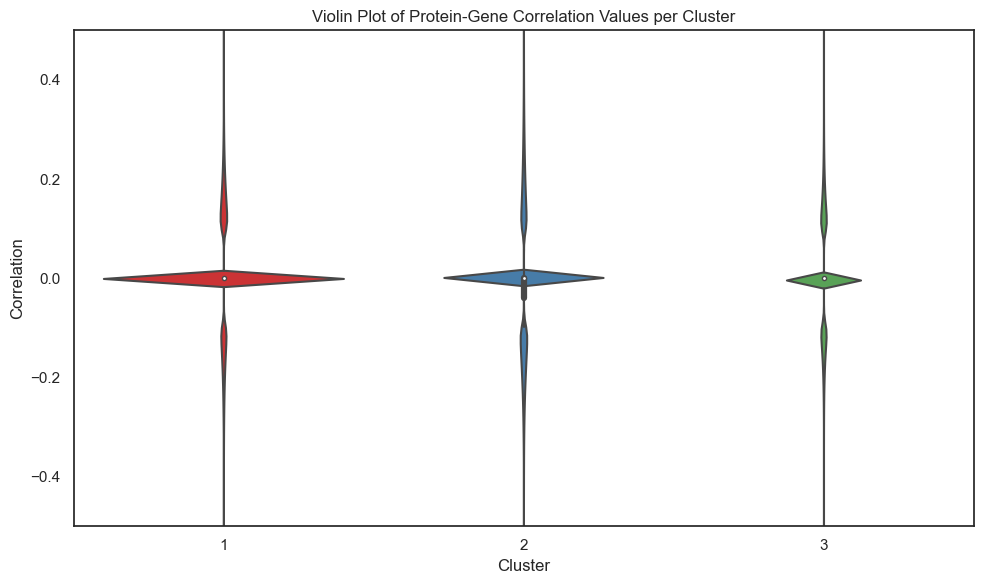

In [ ]:
clusters = sch.fcluster(row_linkage, 3, criterion="maxclust")
data = pearson_clean.copy()
data["Cluster"] = clusters

# 2. Name the index "Protein"
data.index.name = "Protein"

# 3. Reset the index so "Protein" becomes a column
data.reset_index(inplace=True)

# 4. Melt the DataFrame, specifying the correct 'id_vars'
data_melted = data.melt(
    id_vars=["Protein", "Cluster"],
    var_name="Gene",
    value_name="Correlation"
)

# 5. Plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=data_melted, x="Cluster", y="Correlation", palette="Set1")
plt.title("Violin Plot of Protein-Gene Correlation Values per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Correlation")
plt.ylim(-0.3, 0.3)  # Zoom in on y-axis
plt.tight_layout()
plt.show()


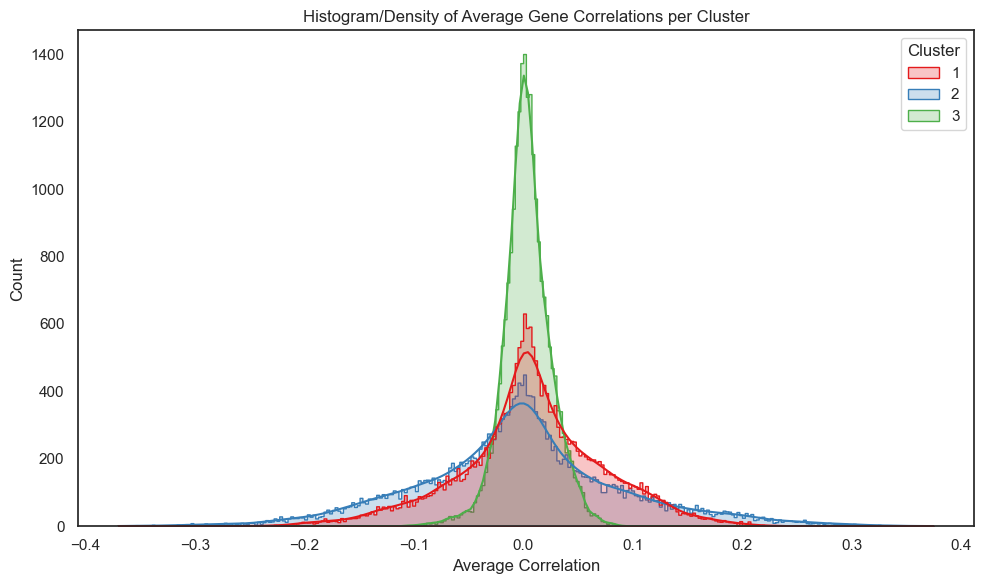

Cluster Centroids (Average Profiles):
             A1BG  A1BG-AS1      A1CF       A2M     A2ML1    A4GALT      AAAS  \
Cluster                                                                         
1        0.052697  0.041527  0.001671 -0.035669 -0.056942 -0.130295  0.135283   
2       -0.118682 -0.096064  0.007399  0.018386  0.089836  0.178380 -0.178830   
3        0.010835  0.011387 -0.011714  0.025667 -0.014039  0.012656 -0.019082   

             AACS    AACSP1     AADAC  ...    ZWILCH     ZWINT      ZXDA  \
Cluster                                ...                                 
1       -0.007268  0.004203 -0.051945  ...  0.008123  0.046601  0.001413   
2        0.056000 -0.000958  0.085343  ... -0.006015 -0.032470  0.003664   
3       -0.006685  0.000653  0.005080  ...  0.007638 -0.005349  0.006116   

             ZXDB      ZXDC    ZYG11A    ZYG11B       ZYX     ZZEF1      ZZZ3  
Cluster                                                                        
1        0.0187

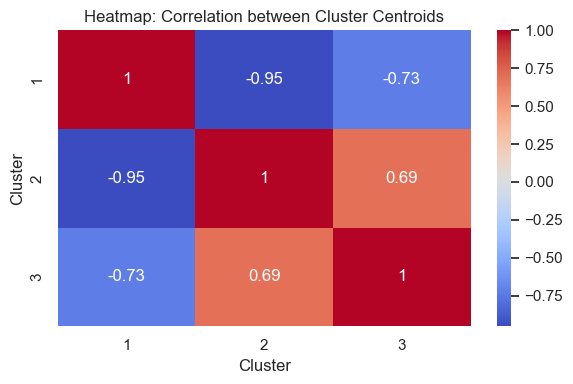


Euclidean distances between Cluster Centroids:
Cluster          1          2          3
Cluster                                 
1         0.000000  24.249598  12.741107
2        24.249598   0.000000  12.355442
3        12.741107  12.355442   0.000000


In [ ]:
# Ensure 'Cluster' column is categorical if it's not numeric
if 'Cluster' in data.columns:
    data['Cluster'] = data['Cluster'].astype(str)  # Convert to string if needed

# (b) Histogram/Density Plot: Distribution of average gene correlations in each cluster.
# Exclude non-numeric columns before computing the mean
numeric_cols = data.select_dtypes(include=['number']).columns  # Select only numeric columns
cluster_averages = data.groupby('Cluster')[numeric_cols].mean()

# Melt the cluster averages (each row: one gene in one cluster, with its average correlation)
cluster_avg_melted = cluster_averages.reset_index().melt(id_vars='Cluster', var_name='Gene', value_name='Avg_Correlation')

# Plot the histogram/density plot
plt.figure(figsize=(10, 6))
sns.histplot(data=cluster_avg_melted, x='Avg_Correlation', hue='Cluster', palette='Set1', kde=True, element='step')
plt.title("Histogram/Density of Average Gene Correlations per Cluster")
plt.xlabel("Average Correlation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


Cluster-Level “Profiles”

In [ ]:
# ----- 2. Cluster-Level “Profiles” ----- #

# Compute the centroid (average profile) for each cluster (across genes)
centroids = cluster_averages  # Already computed

print("Cluster Centroids (Average Profiles):")
print(centroids)

# (a) Compute pairwise correlation between centroids (transposing so genes are observations)
centroid_corr = centroids.T.corr()
print("\nCorrelation between Cluster Centroids:")
print(centroid_corr)

# Plot correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(centroid_corr, annot=True, cmap='coolwarm')
plt.title("Heatmap: Correlation between Cluster Centroids")
plt.tight_layout()
plt.show()

# (b) Compute Euclidean distances between centroids
centroid_dist = pd.DataFrame(squareform(pdist(centroids)), index=centroids.index, columns=centroids.index)

print("\nEuclidean distances between Cluster Centroids:")
print(centroid_dist)

## Correlation networks

In [ ]:
#pip install community
#pip install python-louvain

Note: you may need to restart the kernel to use updated packages.


#### 2 - clusters

In [ ]:
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")


Network Density: 0.022865937175085633
Network Modularity: 0.5617897234205266

Top 5 Hub Proteins (by Degree Centrality):
GNG12: 0.1258
MYO1C: 0.1227
PPP1R8: 0.1215
LMNA: 0.1207
TICAM2: 0.1197


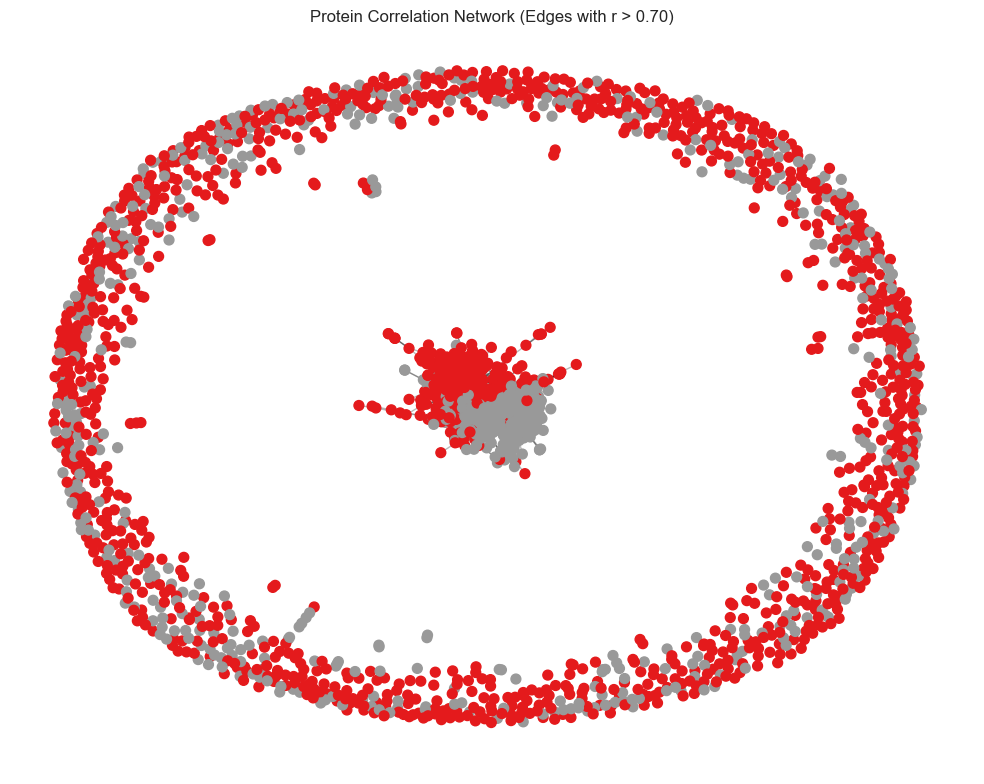

In [ ]:
# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = pearson_clean.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes 
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(pearson_clean.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()

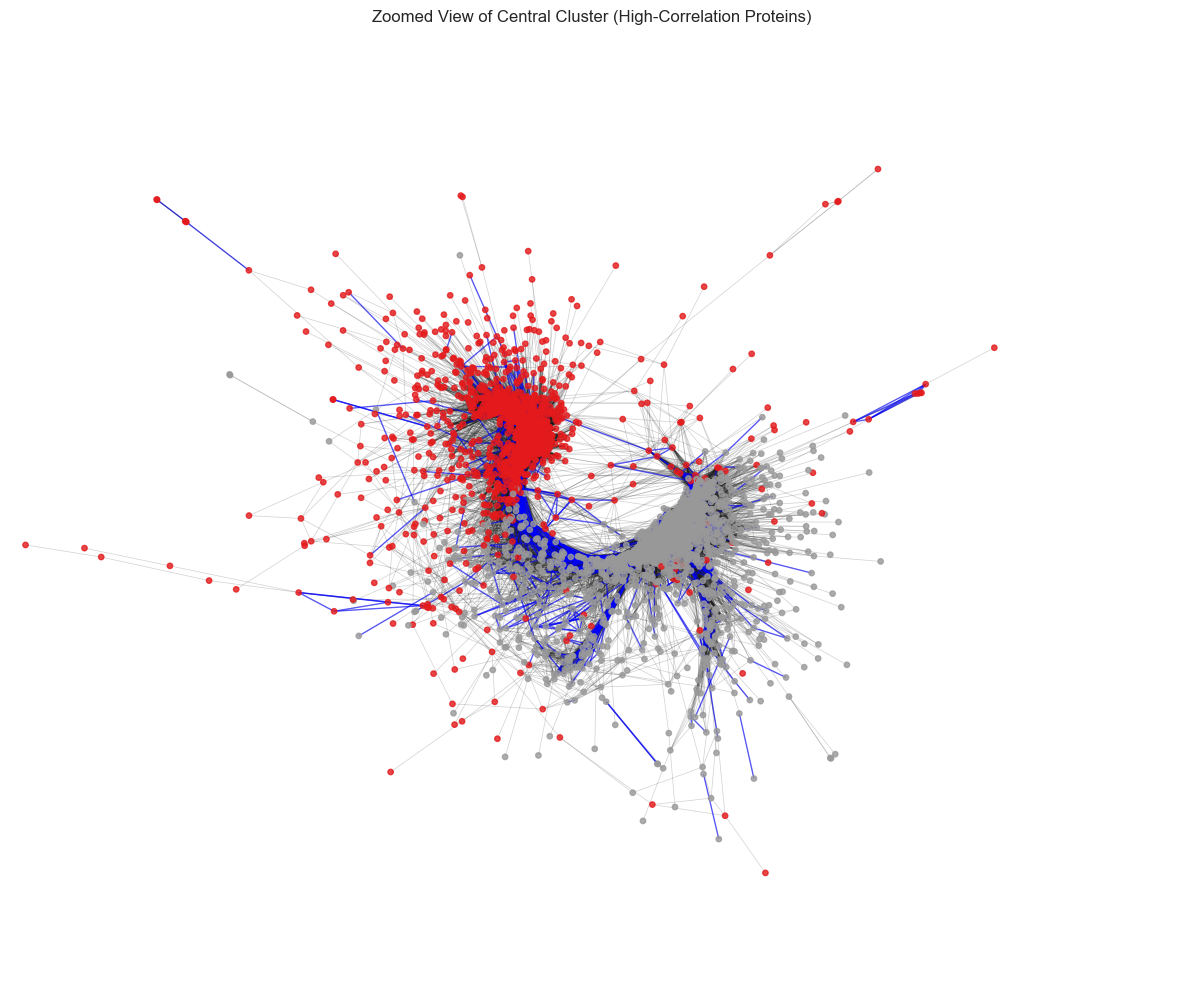

In [ ]:
# Create zoomed version of central cluster
plt.figure(figsize=(12, 10))

# Get the same layout as the original visualization for consistency
pos = nx.spring_layout(G, seed=42)  # Use same seed as original for consistency

# Get the approximate center coordinates
x_coords = [coord[0] for coord in pos.values()]
y_coords = [coord[1] for coord in pos.values()]
center_x = sum(x_coords) / len(x_coords)
center_y = sum(y_coords) / len(y_coords)

# Define radius for central region
radius = 0.3  # Adjust this value to control zoom level

# Identify nodes in the central region
central_nodes = [node for node in G.nodes() if 
                ((pos[node][0] - center_x)**2 + (pos[node][1] - center_y)**2) < radius**2]

# Draw edges with increased transparency for better visibility
central_edge_list = [(u, v) for u, v in G.edges() if u in central_nodes and v in central_nodes]
central_G = nx.Graph()
central_G.add_edges_from(central_edge_list)
nx.draw_networkx_edges(central_G, pos, alpha=0.2, width=0.5)

# Draw high correlation edges more prominently
high_corr_edges = [(u, v) for u, v, d in G.edges(data=True) 
                  if d['weight'] > 0.8 and u in central_nodes and v in central_nodes]
high_corr_G = nx.Graph()
high_corr_G.add_edges_from(high_corr_edges)
nx.draw_networkx_edges(high_corr_G, pos, alpha=0.6, width=1.0, edge_color='blue')

# Draw nodes for central region
central_nodes_colors = [G.nodes[node]['cluster'] for node in central_nodes]
nx.draw_networkx_nodes(G, pos, nodelist=central_nodes, node_size=15, 
                      alpha=0.8, cmap=plt.cm.Set1, node_color=central_nodes_colors)

# Add labels for hub proteins in central region (top 10)
top_hubs = [protein for protein, _ in sorted_hubs[:10]]
#central_hub_labels = {node: node for node in top_hubs if node in central_nodes}
#nx.draw_networkx_labels(G, pos, labels=central_hub_labels, font_size=10, font_color='black', font_weight='bold')

# Set plot limits for zoom effect
plt.xlim(center_x - radius, center_x + radius)
plt.ylim(center_y - radius, center_y + radius)

plt.title("Zoomed View of Central Cluster (High-Correlation Proteins)")
plt.axis("off")
plt.tight_layout()
plt.savefig("zoomed_central_cluster.png", dpi=300)
plt.show()

In [ ]:
# 1. Save the network assignments for each protein
cluster_df = pd.DataFrame({
    'Protein': list(protein_cluster_mapping.keys()),
    'Cluster': list(protein_cluster_mapping.values())
})
cluster_df.to_csv('protein_clusters.csv', index=False)

# 2. Save community detection results (Louvain algorithm)
if 'partition' in locals():
    community_df = pd.DataFrame({
        'Protein': list(partition.keys()),
        'Community': list(partition.values())
    })
    community_df.to_csv('protein_communities.csv', index=False)

# 3. Save network properties of each protein
# Degree centrality
degree_df = pd.DataFrame({
    'Protein': list(degree_centrality.keys()),
    'DegreeCentrality': list(degree_centrality.values())
})

# You could also calculate other centrality measures
betweenness_centrality = nx.betweenness_centrality(G)
closeness_centrality = nx.closeness_centrality(G)

# Add these measures to the dataframe
degree_df['BetweennessCentrality'] = [betweenness_centrality.get(p, 0) for p in degree_df['Protein']]
degree_df['ClosenessCentrality'] = [closeness_centrality.get(p, 0) for p in degree_df['Protein']]

# Add cluster information
degree_df['Cluster'] = [protein_cluster_mapping.get(p, -1) for p in degree_df['Protein']]

# Save to CSV
degree_df.to_csv('protein_network_properties.csv', index=False)

# 4. Save the network edges to a file
edges_list = list(G.edges(data=True))
edge_df = pd.DataFrame([
    {'Protein1': p1, 'Protein2': p2, 'Weight': data.get('weight', 0)} 
    for p1, p2, data in edges_list
])
edge_df.to_csv('protein_network_edges.csv', index=False)

# 5. For more advanced analysis, you could save as GraphML format
# which preserves the full network structure for loading into tools like Cytoscape
nx.write_graphml(G, 'protein_correlation_network.graphml')

print("All network analysis results saved to CSV files")

All network analysis results saved to CSV files


#### 3 - clusters

In [ ]:
clusters = sch.fcluster(row_linkage, 3, criterion="maxclust")


Network Density: 0.022865937175085633
Network Modularity: 0.562635945947008

Top 5 Hub Proteins (by Degree Centrality):
GNG12: 0.1258
MYO1C: 0.1227
PPP1R8: 0.1215
LMNA: 0.1207
TICAM2: 0.1197


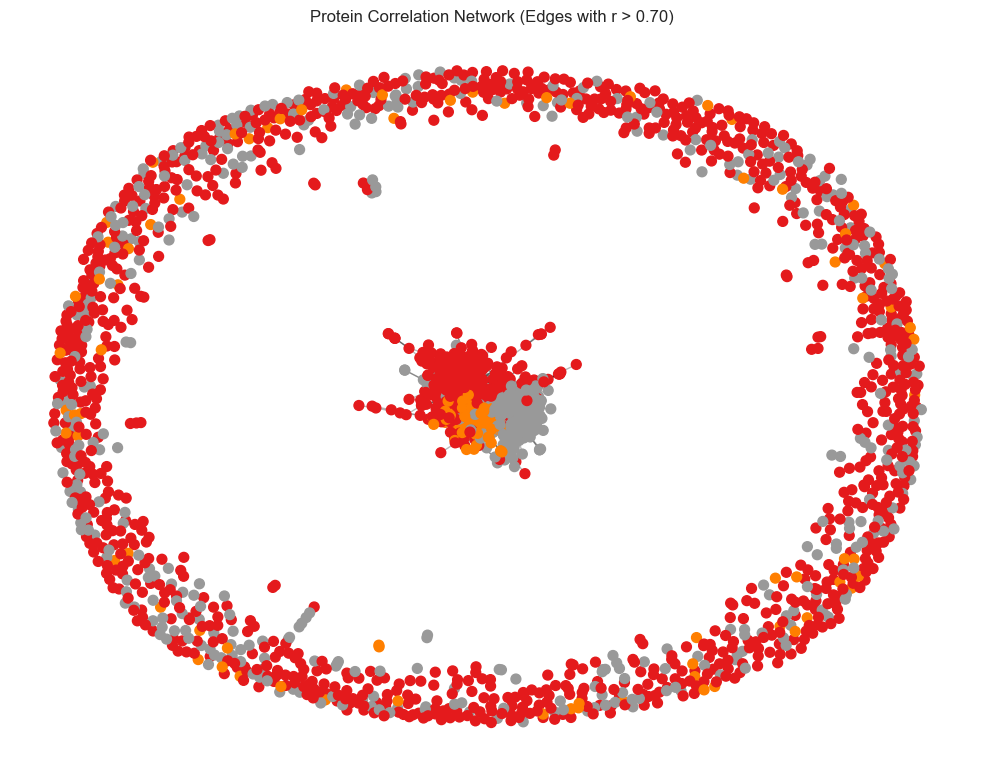

In [ ]:
# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = pearson_clean.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes 
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(pearson_clean.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()

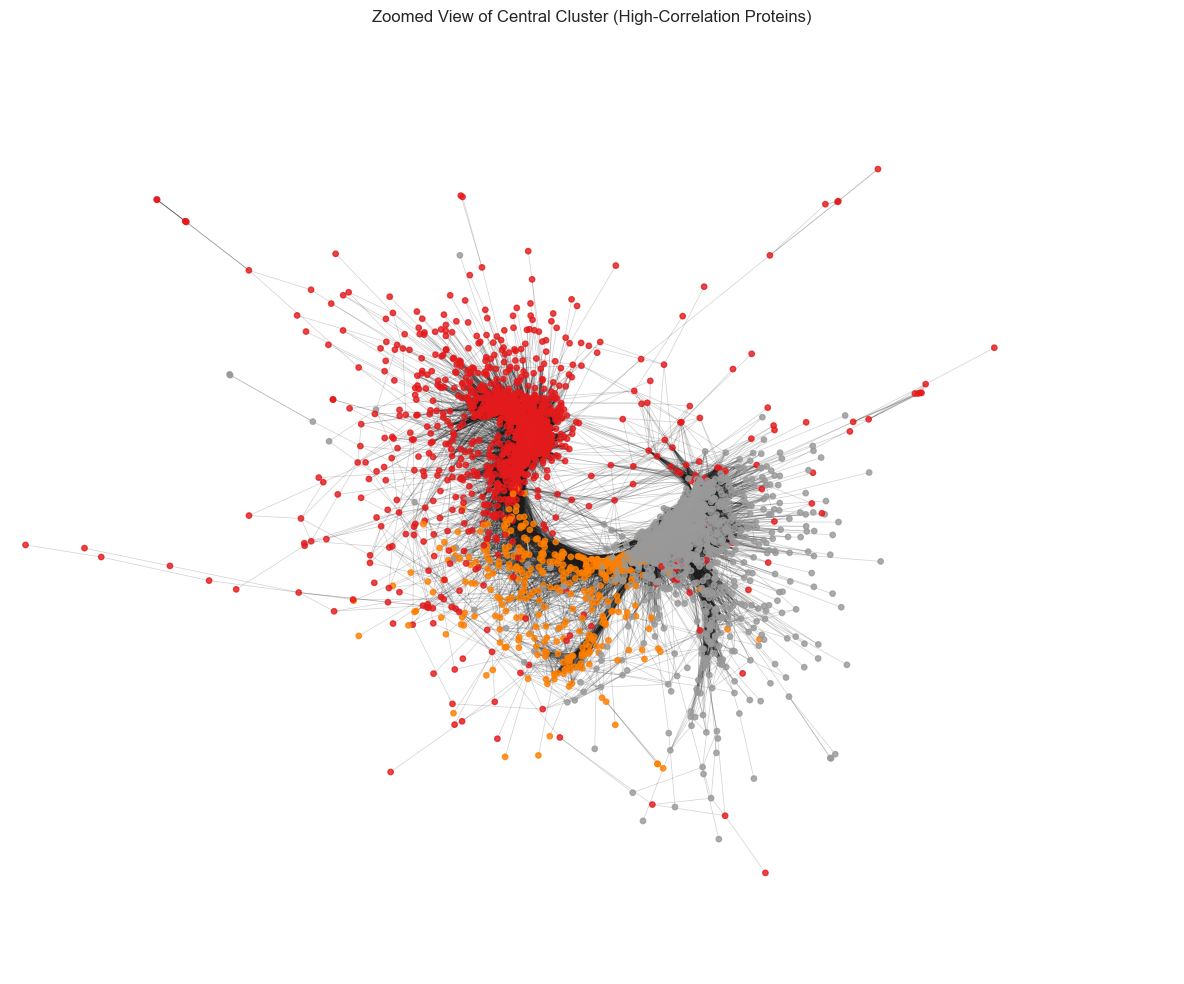

In [ ]:
# Create zoomed version of central cluster
plt.figure(figsize=(12, 10))

# Get the same layout as the original visualization for consistency
pos = nx.spring_layout(G, seed=42)  # Use same seed as original for consistency

# Get the approximate center coordinates
x_coords = [coord[0] for coord in pos.values()]
y_coords = [coord[1] for coord in pos.values()]
center_x = sum(x_coords) / len(x_coords)
center_y = sum(y_coords) / len(y_coords)

# Define radius for central region
radius = 0.3  # Adjust this value to control zoom level

# Identify nodes in the central region
central_nodes = [node for node in G.nodes() if 
                ((pos[node][0] - center_x)**2 + (pos[node][1] - center_y)**2) < radius**2]

# Draw edges with increased transparency for better visibility
central_edge_list = [(u, v) for u, v in G.edges() if u in central_nodes and v in central_nodes]
central_G = nx.Graph()
central_G.add_edges_from(central_edge_list)
nx.draw_networkx_edges(central_G, pos, alpha=0.2, width=0.5)

# Draw high correlation edges more prominently
high_corr_edges = [(u, v) for u, v, d in G.edges(data=True) 
                  if d['weight'] > 0.9 and u in central_nodes and v in central_nodes]
high_corr_G = nx.Graph()
high_corr_G.add_edges_from(high_corr_edges)
nx.draw_networkx_edges(high_corr_G, pos, alpha=0.6, width=1.0, edge_color='lightyellow')


# Draw nodes for central region
central_nodes_colors = [G.nodes[node]['cluster'] for node in central_nodes]
nx.draw_networkx_nodes(G, pos, nodelist=central_nodes, node_size=15, 
                      alpha=0.8, cmap=plt.cm.Set1, node_color=central_nodes_colors)

# Add labels for hub proteins in central region (top 10)
top_hubs = [protein for protein, _ in sorted_hubs[:10]]
#central_hub_labels = {node: node for node in top_hubs if node in central_nodes}
#nx.draw_networkx_labels(G, pos, labels=central_hub_labels, font_size=10, font_color='black', font_weight='bold')

# Set plot limits for zoom effect
plt.xlim(center_x - radius, center_x + radius)
plt.ylim(center_y - radius, center_y + radius)

plt.title("Zoomed View of Central Cluster (High-Correlation Proteins)")
plt.axis("off")
plt.tight_layout()
plt.savefig("zoomed_central_cluster.png", dpi=300)
plt.show()

### Protein - Protein and protein expression networks

In [13]:
proteins = load('data/full_prot.joblib')
proteins

,A2M,AAAS,AACS,AAGAB,AAK1,AAMDC,AAMP,AAR2,AARS,AARS2,...,ZNF787,ZNF800,ZNF830,ZNHIT6,ZNRD1,ZRANB2,ZW10,ZWILCH,ZYX,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,1.000000,0.000000,0.000000,0.000000,0.225561,0.000000,0.121652,0.143729,0.000000,0.000000,...,-0.170119,0.000000,-0.192738,0.000000,0.000000,-0.146868,0.000000,0.000000,0.114483,0.000000
AAAS,0.000000,1.000000,-0.233390,-0.345984,0.000000,-0.388692,-0.281584,0.216806,-0.294110,0.334116,...,-0.153136,0.167936,0.000000,0.181163,0.000000,0.000000,0.293679,0.000000,-0.186656,0.000000
AACS,0.000000,-0.218348,1.000000,0.321220,0.242881,0.245037,0.273681,0.196180,0.425103,0.000000,...,-0.112829,0.000000,-0.284120,-0.198949,-0.413636,-0.228468,0.312351,0.478636,0.136107,-0.403005
AAGAB,0.000000,-0.340601,0.326584,1.000000,0.160591,0.333963,0.490817,0.122178,0.477098,-0.249742,...,0.000000,-0.205432,0.000000,0.000000,0.000000,0.000000,0.000000,0.433279,0.207931,-0.133559
AAK1,0.224240,-0.128369,0.241084,0.154089,1.000000,0.169175,0.302847,0.236585,0.293882,0.000000,...,-0.183840,0.000000,-0.339322,-0.181509,-0.299583,-0.200646,0.191614,0.267412,0.427129,-0.312405
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,-0.149387,0.000000,-0.228664,0.000000,-0.197585,0.180600,0.000000,-0.173096,0.000000,0.000000,...,0.297751,0.000000,0.424778,0.178508,0.421273,1.000000,-0.290277,-0.118772,0.000000,0.448726
ZW10,0.000000,0.301440,0.301829,0.000000,0.170618,0.000000,0.000000,0.380405,0.162413,0.183555,...,-0.212251,0.152209,-0.375406,0.000000,-0.370570,-0.299930,1.000000,0.450707,0.000000,-0.442071
ZWILCH,0.000000,0.000000,0.486649,0.444735,0.268711,0.301823,0.438029,0.368233,0.541679,-0.113909,...,0.000000,0.000000,-0.205280,0.000000,-0.273549,-0.118606,0.453857,1.000000,0.243504,-0.344517


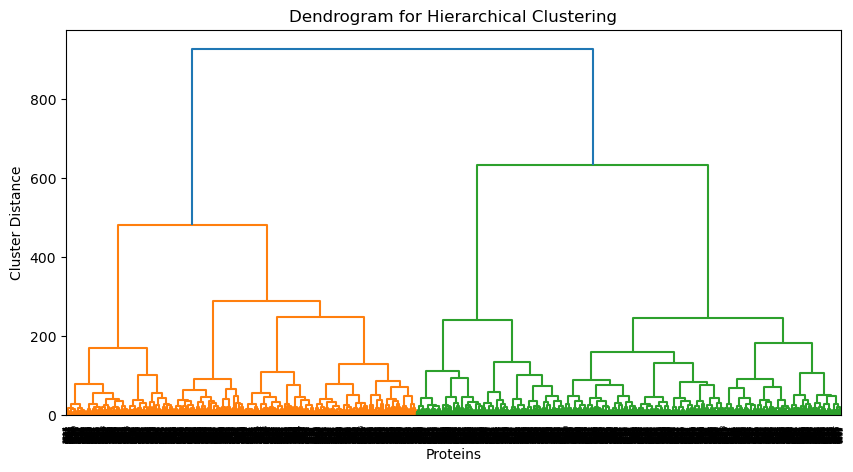

In [14]:
row_linkage1 = sch.linkage(proteins, method="ward", metric="euclidean")
corr_utils.plot_dendrogram(row_linkage1)


Network Density: 0.1233200100269129
Network Modularity: 0.618978060934395

Top 5 Hub Proteins (by Degree Centrality):
CCDC47: 0.2502
FAF2: 0.2433
MRPL37: 0.2432
MTG1: 0.2412
MFN1: 0.2408


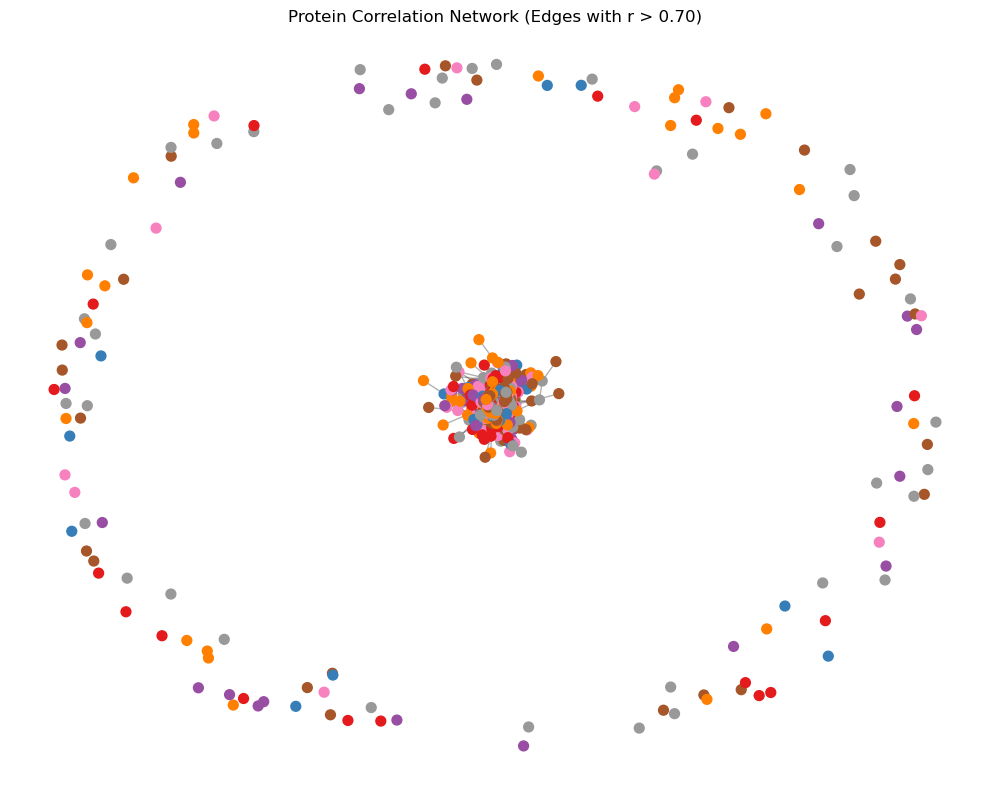

In [16]:
# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = proteins.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes 
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(proteins.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()

PCA

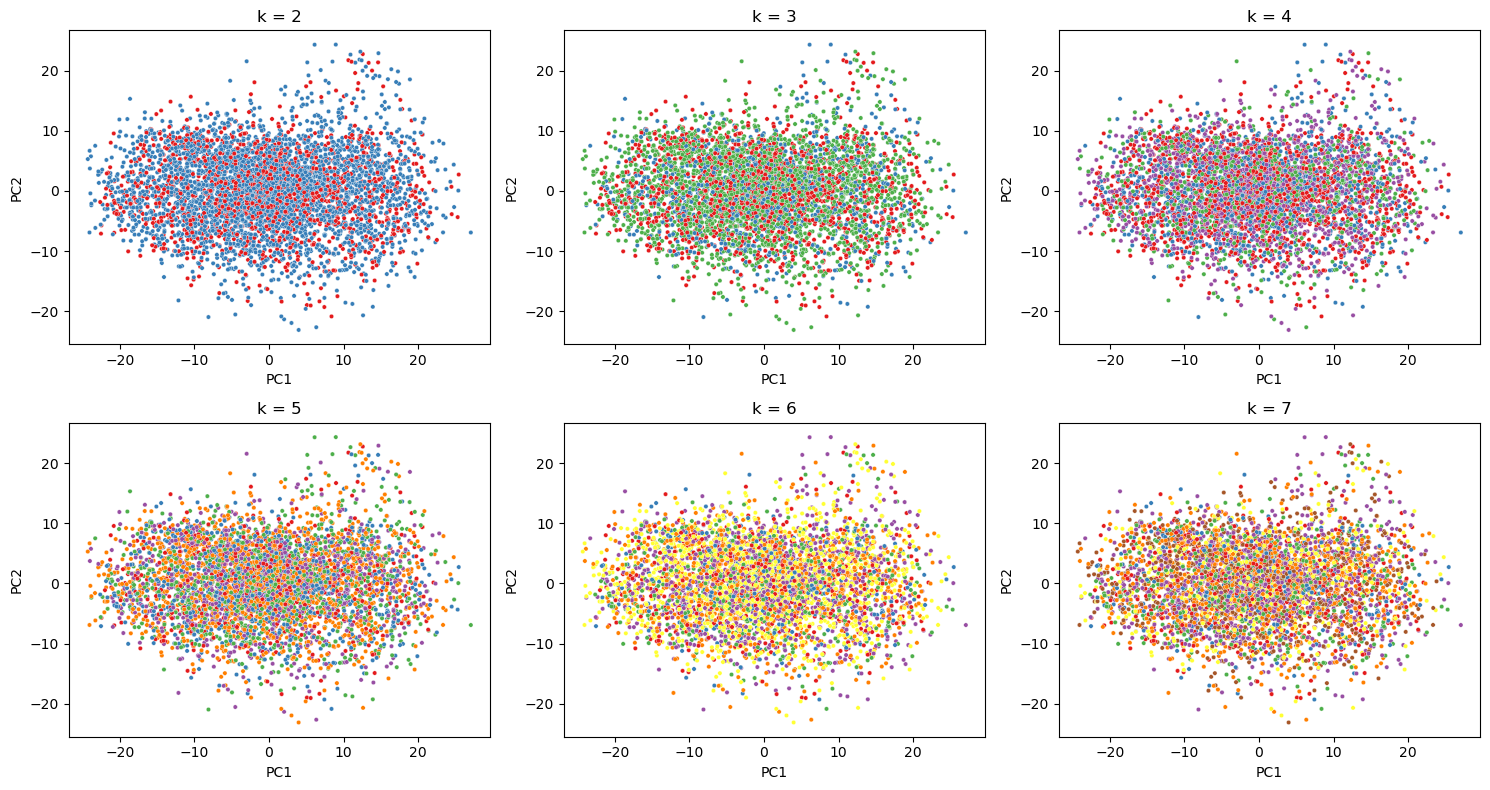

In [ ]:
clusters = sch.fcluster(row_linkage1, 2, criterion="maxclust")
# Create a 2x5 grid for plots with a reduced overall figure size
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # flatten to easily iterate over

# Loop over cluster numbers from 2 to 10
for i, k in enumerate(range(2, 8)):
    # Compute clusters using hierarchical clustering
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")
    
    # Perform PCA on the cleaned data
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(protein_expr.values)
    
    # Create DataFrame for PCA results with cluster assignments
    pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=protein_expr.index)
    pca_df["Cluster"] = clusters
    
    # Plot on the corresponding axis
    ax = axes[i]
    sns.scatterplot(
        data=pca_df, 
        x="PC1", 
        y="PC2", 
        hue="Cluster", 
        palette="Set1", 
        s=10, 
        ax=ax,
        legend=False  # Disable legend for individual subplots
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

Network

#### Expressions

In [24]:
protein_expr = load('data/proteomics_matched.joblib')
protein_expr = protein_expr.T

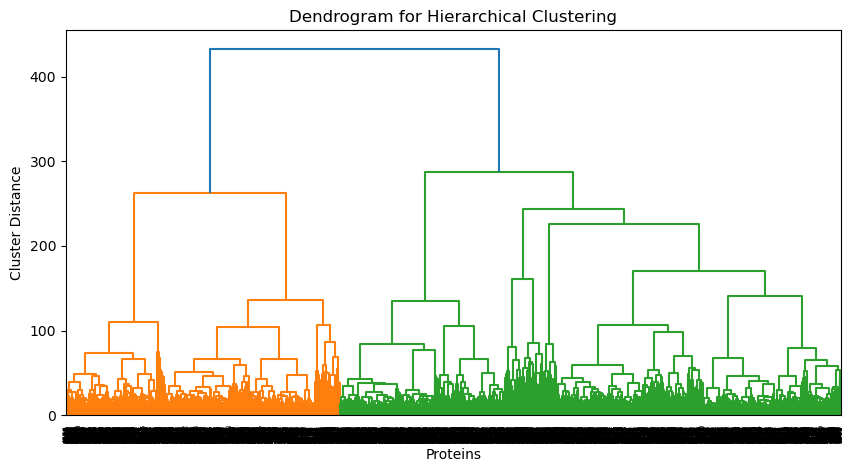

In [25]:
row_linkage2 = sch.linkage(protein_expr, method="ward", metric="euclidean")
corr_utils.plot_dendrogram(row_linkage2)

PCA

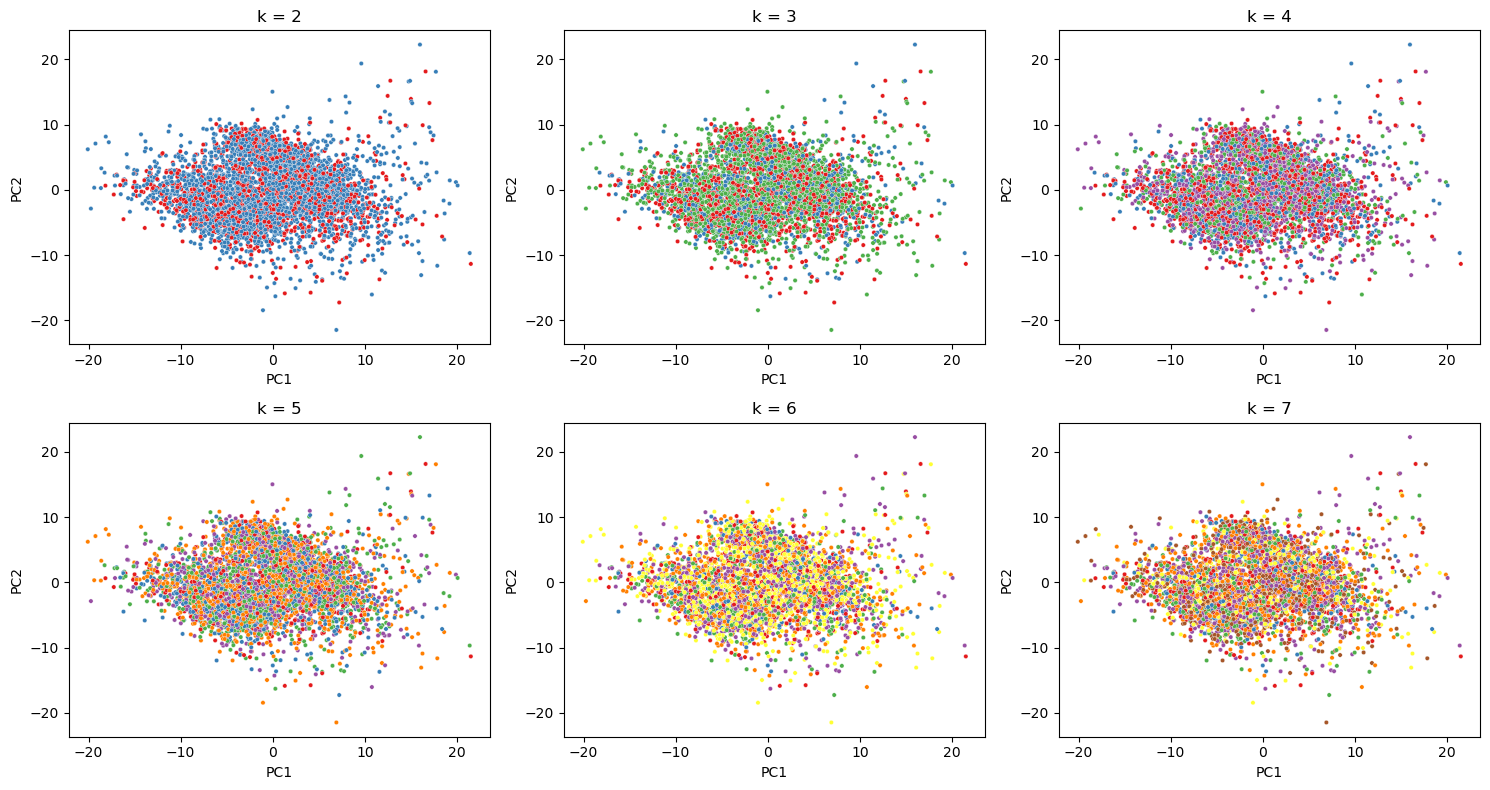

In [30]:

clusters = sch.fcluster(row_linkage2, 2, criterion="maxclust")
# Create a 2x5 grid for plots with a reduced overall figure size
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # flatten to easily iterate over
# Loop over cluster numbers from 2 to 10
for i, k in enumerate(range(2, 8)):
    # Compute clusters using hierarchical clustering
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")
    
    # Perform PCA on the cleaned data
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(protein_expr.values)
    
    # Create DataFrame for PCA results with cluster assignments
    pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=protein_expr.index)
    pca_df["Cluster"] = clusters
    
    # Plot on the corresponding axis
    ax = axes[i]
    sns.scatterplot(
        data=pca_df, 
        x="PC1", 
        y="PC2", 
        hue="Cluster", 
        palette="Set1", 
        s=10, 
        ax=ax,
        legend=False  # Disable legend for individual subplots
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [ ]:
# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = protein_expr.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes 
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(protein_expr.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()